# 泰坦尼克号生存预测

这是我第一次做完整的机器学习项目，记录整个思考和分析过程。

**问题定义：** 根据乘客信息（年龄、性别、船舱等级等），预测其在泰坦尼克号沉船中是否能生存。

**数据来源：** Kaggle Titanic 竞赛数据集

---
**分析步骤：**
1. 数据加载与初步了解
2. 探索性数据分析（EDA）
3. 数据清洗与特征工程
4. 建立机器学习模型（Pipeline + 交叉验证）
5. 模型对比与调优
6. 生成预测结果

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.utils.validation import check_is_fitted
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

warnings.filterwarnings('ignore')

# ── 暗色主题配置 ──────────────────────────────────────────────────────────
BG     = '#2b2b2b'
FG     = 'white'
TITLE  = '#f4a261'
SPINE  = '#cfcfcf'
GRID_C = '#888888'

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial']
plt.rcParams['axes.unicode_minus'] = False


def dark_ax(ax, title='', xlabel='', ylabel='', grid_axis='both'):
    ax.set_facecolor(BG)
    ax.figure.set_facecolor(BG)
    if title:
        ax.set_title(title, fontsize=14, color=TITLE, pad=10)
    if xlabel:
        ax.set_xlabel(xlabel, fontsize=12, color=FG)
    if ylabel:
        ax.set_ylabel(ylabel, fontsize=12, color=FG)
    ax.tick_params(colors=FG, labelsize=11)
    for spine in ax.spines.values():
        spine.set_color(SPINE)
        spine.set_linewidth(1.2)
    if grid_axis:
        ax.grid(True, axis=grid_axis, linestyle='--', alpha=0.3, color=GRID_C)


def save_fig(fig, path):
    fig.savefig(path, dpi=130, bbox_inches='tight', facecolor=BG)


print('库导入完成')


库导入完成


## 第一步：加载数据

In [2]:
train = pd.read_csv('data/titanic/train.csv')
test  = pd.read_csv('data/titanic/test.csv')

print(f'训练集：{train.shape[0]} 行，{train.shape[1]} 列')
print(f'测试集：{test.shape[0]} 行，{test.shape[1]} 列')
train.head()


训练集：891 行，12 列
测试集：418 行，11 列


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
print('=== 训练集基本信息 ===')
train.info()
print()
print('=== 数值列统计摘要 ===')
train.describe()


=== 训练集基本信息 ===
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB

=== 数值列统计摘要 ===


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


## 第二步：探索性数据分析（EDA）

从宏观角度理解数据，再逐一分析各特征与生存率的关系。

In [4]:
# 缺失值统计
print('=== 训练集缺失值 ===')
miss = train.isnull().sum()
pct  = (miss / len(train) * 100).round(2)
print(pd.DataFrame({'缺失数量': miss, '缺失比例(%)': pct})[miss > 0])

print()
print('=== 测试集缺失值 ===')
miss2 = test.isnull().sum()
pct2  = (miss2 / len(test) * 100).round(2)
print(pd.DataFrame({'缺失数量': miss2, '缺失比例(%)': pct2})[miss2 > 0])


=== 训练集缺失值 ===
          缺失数量  缺失比例(%)
Age        177    19.87
Cabin      687    77.10
Embarked     2     0.22

=== 测试集缺失值 ===
       缺失数量  缺失比例(%)
Age      86    20.57
Fare      1     0.24
Cabin   327    78.23


遇难：549 人 (61.6%)，生还：342 人 (38.4%)


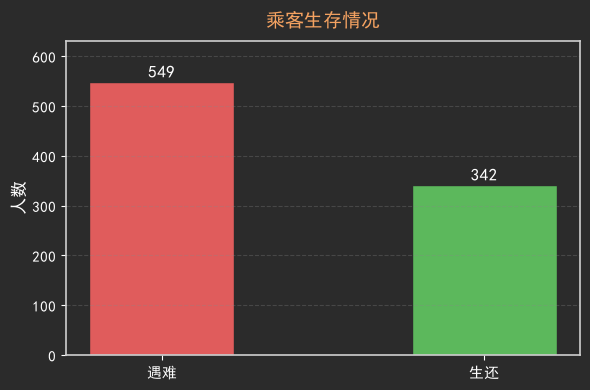

In [5]:
# 图 1：整体生存情况
cnt = train['Survived'].value_counts()
print(f'遇难：{cnt[0]} 人 ({cnt[0]/len(train)*100:.1f}%)，'
      f'生还：{cnt[1]} 人 ({cnt[1]/len(train)*100:.1f}%)')

fig, ax = plt.subplots(figsize=(6, 4), facecolor=BG)
colors = ['#e05c5c', '#5cb85c']
bars = ax.bar(['遇难', '生还'], cnt.values, color=colors, width=0.45, edgecolor=BG)
for bar, v in zip(bars, cnt.values):
    ax.text(bar.get_x() + bar.get_width()/2, v + 8, str(v),
            ha='center', fontsize=12, color=FG)
dark_ax(ax, title='乘客生存情况', ylabel='人数', grid_axis='y')
ax.set_ylim(0, max(cnt.values) * 1.15)
plt.tight_layout()
save_fig(fig, 'plot_01_survival_overall.png')
plt.show()


各性别生存率： {'female': 0.742, 'male': 0.189}


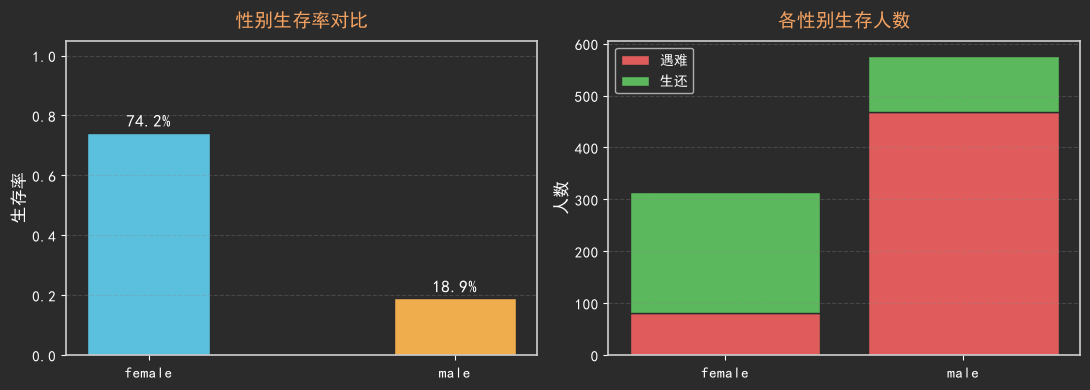

In [6]:
# 图 2：性别与生存率
sex_surv = train.groupby('Sex')['Survived'].mean()
print('各性别生存率：', sex_surv.round(3).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(11, 4), facecolor=BG)

bars = axes[0].bar(sex_surv.index, sex_surv.values,
                   color=['#5bc0de', '#f0ad4e'], width=0.4, edgecolor=BG)
for bar, val in zip(bars, sex_surv.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, val + 0.02,
                f'{val:.1%}', ha='center', fontsize=12, color=FG)
axes[0].set_ylim(0, 1.05)
dark_ax(axes[0], title='性别生存率对比', ylabel='生存率', grid_axis='y')

sex_cnt = train.groupby(['Sex', 'Survived']).size().unstack(fill_value=0)
x = range(len(sex_cnt))
axes[1].bar(x, sex_cnt[0], label='遇难', color='#e05c5c', edgecolor=BG)
axes[1].bar(x, sex_cnt[1], bottom=sex_cnt[0], label='生还',
            color='#5cb85c', edgecolor=BG)
axes[1].set_xticks(list(x))
axes[1].set_xticklabels(sex_cnt.index)
axes[1].legend(facecolor=BG, edgecolor=SPINE, labelcolor=FG)
dark_ax(axes[1], title='各性别生存人数', ylabel='人数', grid_axis='y')

plt.tight_layout()
save_fig(fig, 'plot_02_sex_survival.png')
plt.show()


各舱等生存率： {1: 0.63, 2: 0.473, 3: 0.242}


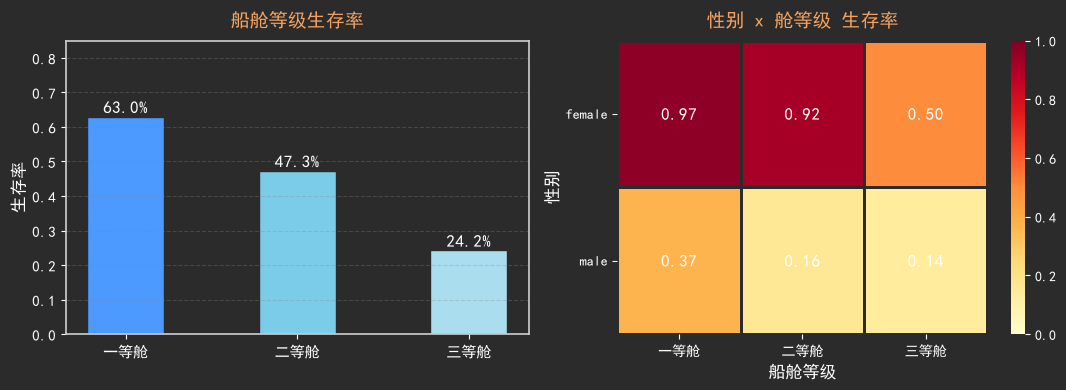

In [7]:
# 图 3：船舱等级与生存率
pc_surv = train.groupby('Pclass')['Survived'].mean()
print('各舱等生存率：', pc_surv.round(3).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(11, 4), facecolor=BG)

labels = ['一等舱', '二等舱', '三等舱']
bars = axes[0].bar(labels, pc_surv.values,
                   color=['#4C9AFF', '#7BCCE8', '#AADDEE'],
                   width=0.45, edgecolor=BG)
for bar, val in zip(bars, pc_surv.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, val + 0.01,
                f'{val:.1%}', ha='center', fontsize=12, color=FG)
axes[0].set_ylim(0, 0.85)
dark_ax(axes[0], title='船舱等级生存率', ylabel='生存率', grid_axis='y')

pivot = train.pivot_table(values='Survived', index='Sex',
                          columns='Pclass', aggfunc='mean')
sns.heatmap(pivot, annot=True, fmt='.2f', cmap='YlOrRd', ax=axes[1],
            linewidths=1, linecolor=BG, vmin=0, vmax=1,
            annot_kws={'color': 'white', 'fontsize': 12})
axes[1].set_xticklabels(['一等舱', '二等舱', '三等舱'], color=FG)
axes[1].set_yticklabels(axes[1].get_yticklabels(), color=FG, rotation=0)
axes[1].set_xlabel('船舱等级', color=FG, fontsize=12)
axes[1].set_ylabel('性别', color=FG, fontsize=12)
axes[1].set_title('性别 x 舱等级 生存率', fontsize=14, color=TITLE, pad=10)
axes[1].tick_params(colors=FG)
axes[1].figure.set_facecolor(BG)
axes[1].set_facecolor(BG)
cbar = axes[1].collections[0].colorbar
cbar.ax.yaxis.set_tick_params(color=FG)
plt.setp(cbar.ax.yaxis.get_ticklabels(), color=FG)

plt.tight_layout()
save_fig(fig, 'plot_03_pclass_survival.png')
plt.show()


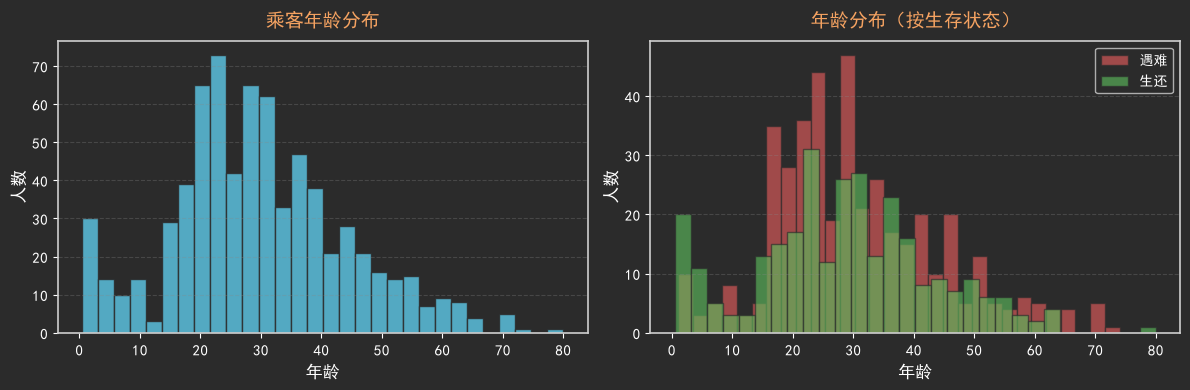

年龄均值：29.7，中位数：28.0


In [8]:
# 图 4：年龄分布
fig, axes = plt.subplots(1, 2, figsize=(12, 4), facecolor=BG)

axes[0].hist(train['Age'].dropna(), bins=30,
             color='#5bc0de', edgecolor=BG, alpha=0.85)
dark_ax(axes[0], title='乘客年龄分布', xlabel='年龄', ylabel='人数', grid_axis='y')

d0 = train[train['Survived'] == 0]['Age'].dropna()
d1 = train[train['Survived'] == 1]['Age'].dropna()
axes[1].hist(d0, bins=30, alpha=0.65, color='#e05c5c', label='遇难', edgecolor=BG)
axes[1].hist(d1, bins=30, alpha=0.65, color='#5cb85c', label='生还', edgecolor=BG)
axes[1].legend(facecolor=BG, edgecolor=SPINE, labelcolor=FG)
dark_ax(axes[1], title='年龄分布（按生存状态）',
        xlabel='年龄', ylabel='人数', grid_axis='y')

plt.tight_layout()
save_fig(fig, 'plot_04_age_distribution.png')
plt.show()

print(f'年龄均值：{train["Age"].mean():.1f}，中位数：{train["Age"].median():.1f}')


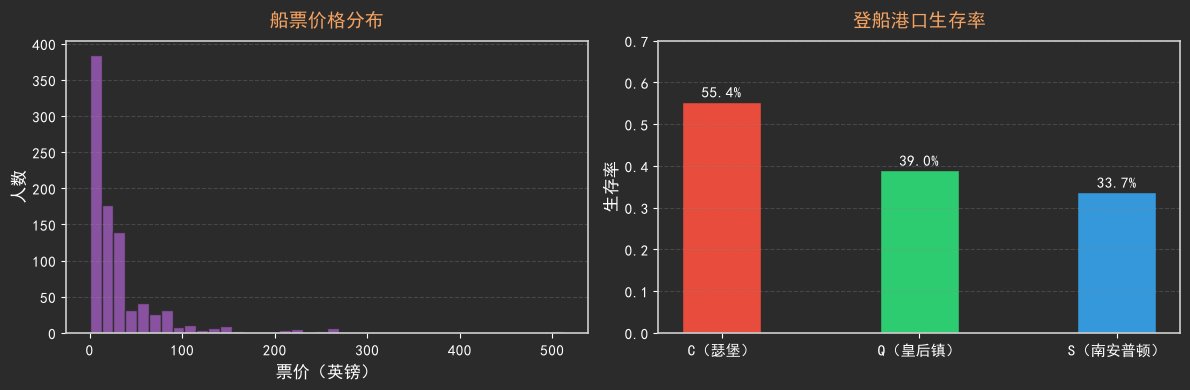

In [9]:
# 图 5：票价分布 & 登船港口生存率
fig, axes = plt.subplots(1, 2, figsize=(12, 4), facecolor=BG)

axes[0].hist(train['Fare'], bins=40,
             color='#9b59b6', edgecolor=BG, alpha=0.85)
dark_ax(axes[0], title='船票价格分布', xlabel='票价（英镑）', ylabel='人数',
        grid_axis='y')

emb_surv   = train.groupby('Embarked')['Survived'].mean()
emb_labels = ['C（瑟堡）', 'Q（皇后镇）', 'S（南安普顿）']
bars = axes[1].bar(emb_labels, emb_surv.values,
                   color=['#e74c3c', '#2ecc71', '#3498db'],
                   width=0.4, edgecolor=BG)
for bar, val in zip(bars, emb_surv.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, val + 0.01,
                f'{val:.1%}', ha='center', fontsize=11, color=FG)
axes[1].set_ylim(0, 0.7)
dark_ax(axes[1], title='登船港口生存率', ylabel='生存率', grid_axis='y')

plt.tight_layout()
save_fig(fig, 'plot_05_fare_embarked.png')
plt.show()


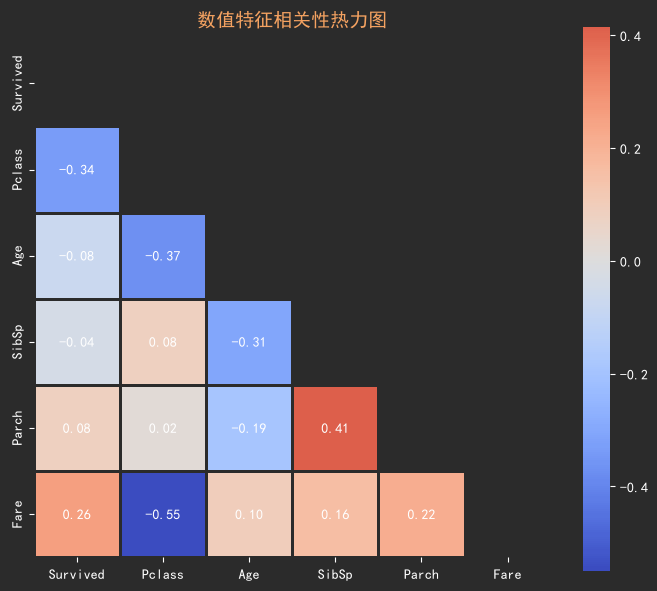

与 Survived 的相关系数（降序）：
Fare      0.257307
Parch     0.081629
SibSp    -0.035322
Age      -0.077221
Pclass   -0.338481
Name: Survived, dtype: float64


In [10]:
# 图 6：数值特征相关性热力图
num_cols    = ['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
corr_matrix = train[num_cols].corr()

fig, ax = plt.subplots(figsize=(7, 6), facecolor=BG)
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f',
            cmap='coolwarm', center=0, ax=ax,
            linewidths=1, linecolor=BG, square=True,
            annot_kws={'color': FG, 'fontsize': 10})
ax.set_title('数值特征相关性热力图', fontsize=14, color=TITLE, pad=10)
ax.tick_params(colors=FG, labelsize=10)
ax.set_facecolor(BG)
ax.figure.set_facecolor(BG)
cbar = ax.collections[0].colorbar
cbar.ax.yaxis.set_tick_params(color=FG)
plt.setp(cbar.ax.yaxis.get_ticklabels(), color=FG)

plt.tight_layout()
save_fig(fig, 'plot_06_correlation.png')
plt.show()

print('与 Survived 的相关系数（降序）：')
print(corr_matrix['Survived'].sort_values(ascending=False).drop('Survived'))


## 第三步：数据清洗与特征工程

先划分原始乘客数据。需要学习统计量的处理放入 `TitanicFeatures` 转换器：`fit` 只读取当次训练部分，`transform` 使用保存的统计量。

- Age：按「头衔 + 性别 + 舱等」的训练中位数填充；未见分组使用训练乘客年龄的整体中位数。
- Embarked、Fare：使用当次训练部分的众数、同舱等中位数。
- FareBin：保存训练票价的四分位点，两端固定为负无穷/正无穷，单行与整批预测使用相同边界。
- Title、家庭规模、船舱记录等确定性特征在 transform 中生成。

交叉验证和网格搜索都通过 Pipeline 每折重新 fit，不提前处理全量数据。

In [11]:
def extract_title(df):
    '''从 Name 列提取头衔，归并稀有类别'''
    title_map = {
        'Mr': 'Mr', 'Mrs': 'Mrs', 'Miss': 'Miss', 'Master': 'Master',
        'Mlle': 'Miss', 'Ms': 'Mrs', 'Mme': 'Mrs',
        'Dr': 'Rare', 'Rev': 'Rare', 'Col': 'Rare', 'Major': 'Rare',
        'Countess': 'Rare', 'Lady': 'Rare', 'Jonkheer': 'Rare',
        'Don': 'Rare', 'Dona': 'Rare', 'Capt': 'Rare', 'Sir': 'Rare',
    }
    raw = df['Name'].str.extract(r',\s*([^.]+)\.', expand=False).str.strip()
    return raw.map(title_map).fillna('Rare')


class TitanicFeatures(TransformerMixin, BaseEstimator):
    """只在 fit 学习统计量；transform 不读取其他乘客的分布。"""

    feature_names = [
        'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare',
        'Embarked', 'Title', 'FamilySize', 'IsAlone', 'HasCabin',
        'AgeBin', 'FareBin'
    ]

    def fit(self, X, y=None):
        d = X.copy()
        d['Title'] = extract_title(d)
        self.embarked_mode_ = d['Embarked'].mode()[0]
        self.fare_medians_ = d.groupby('Pclass')['Fare'].median()
        self.age_medians_ = d.groupby(['Title', 'Sex', 'Pclass'])['Age'].median()
        self.global_age_median_ = d['Age'].median()
        filled_fare = d['Fare'].fillna(d['Pclass'].map(self.fare_medians_))
        self.fare_edges_ = np.r_[
            -np.inf, filled_fare.quantile([0.25, 0.5, 0.75]).to_numpy(), np.inf
        ]
        return self

    def transform(self, X):
        check_is_fitted(self, 'fare_edges_')
        d = X.copy()
        d['Title'] = extract_title(d)
        d['Embarked'] = d['Embarked'].fillna(self.embarked_mode_)
        d['Fare'] = d['Fare'].fillna(d['Pclass'].map(self.fare_medians_))
        for (title, sex, pclass), median in self.age_medians_.items():
            mask = (d['Age'].isna() & (d['Title'] == title) &
                    (d['Sex'] == sex) & (d['Pclass'] == pclass))
            d.loc[mask, 'Age'] = median
        d['Age'] = d['Age'].fillna(self.global_age_median_)

        d['HasCabin'] = d['Cabin'].notna().astype(int)
        d['FamilySize'] = d['SibSp'] + d['Parch'] + 1
        d['IsAlone'] = (d['FamilySize'] == 1).astype(int)
        d['AgeBin'] = pd.cut(
            d['Age'], bins=[-np.inf, 12, 18, 35, 60, np.inf], labels=False
        ).astype(int)
        d['FareBin'] = pd.cut(
            d['Fare'], bins=self.fare_edges_, labels=False, include_lowest=True
        ).astype(int)
        d['Sex'] = (d['Sex'] == 'female').astype(int)
        d['Embarked'] = d['Embarked'].map({'S': 0, 'C': 1, 'Q': 2}).fillna(0).astype(int)
        d['Title'] = d['Title'].map(
            {'Mr': 0, 'Mrs': 1, 'Miss': 2, 'Master': 3, 'Rare': 4}
        ).fillna(4).astype(int)
        return d[self.feature_names]

    def get_feature_names_out(self, input_features=None):
        return np.array(self.feature_names, dtype=object)


# 保持原始数据，等 Pipeline.fit 时再学习预处理统计量
X = train.drop(columns='Survived')
y = train['Survived'].astype(int)
X_pred = test.copy()
print(f'原始训练数据：{X.shape}，测试数据：{X_pred.shape}')
print('标签分布：')
print(y.value_counts())


原始训练数据：(891, 11)，测试数据：(418, 11)
标签分布：
Survived
0    549
1    342
Name: count, dtype: int64


## 第四步：建立并比较多个机器学习模型

先划分原始数据，再用 `Pipeline` 串联特征工程、标准化和模型。每一折的填充值、分位点和标准化统计量只来自当折训练部分。

树模型不需要标准化；这里保留统一的 Pipeline 结构。模型依据训练部分的 CV 均值选择，留出验证集用于报告表现，不用于选择模型或参数。

In [12]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Pipeline：特征工程 + Scaler + 模型，CV 每折独立拟合所有统计量
# 树模型不需要标准化，但放进 Pipeline 不影响结果，保持结构统一
def make_pipe(clf):
    return Pipeline([('features', TitanicFeatures()),
                     ('scaler', StandardScaler()), ('clf', clf)])


models = {
    '逻辑回归':   make_pipe(LogisticRegression(max_iter=500, random_state=42)),
    '决策树':     make_pipe(DecisionTreeClassifier(random_state=42)),
    '随机森林':   make_pipe(RandomForestClassifier(n_estimators=100, random_state=42)),
    '梯度提升树': make_pipe(GradientBoostingClassifier(n_estimators=100, random_state=42)),
    '支持向量机': make_pipe(SVC(kernel='rbf', random_state=42)),
}

results = {}
for name, pipe in models.items():
    cv = cross_val_score(pipe, X_train, y_train, cv=5, scoring='accuracy')
    pipe.fit(X_train, y_train)
    val_acc = accuracy_score(y_val, pipe.predict(X_val))
    results[name] = {'CV均值': cv.mean(), 'CV标准差': cv.std(), '验证': val_acc}
    print(f'{name:8s}  CV={cv.mean():.4f}(+-{cv.std():.4f})  验证={val_acc:.4f}')
print('完成')


逻辑回归      CV=0.8062(+-0.0288)  验证=0.8045
决策树       CV=0.7599(+-0.0247)  验证=0.7709


随机森林      CV=0.7936(+-0.0309)  验证=0.8101


梯度提升树     CV=0.8218(+-0.0419)  验证=0.8101
支持向量机     CV=0.8189(+-0.0192)  验证=0.8212
完成


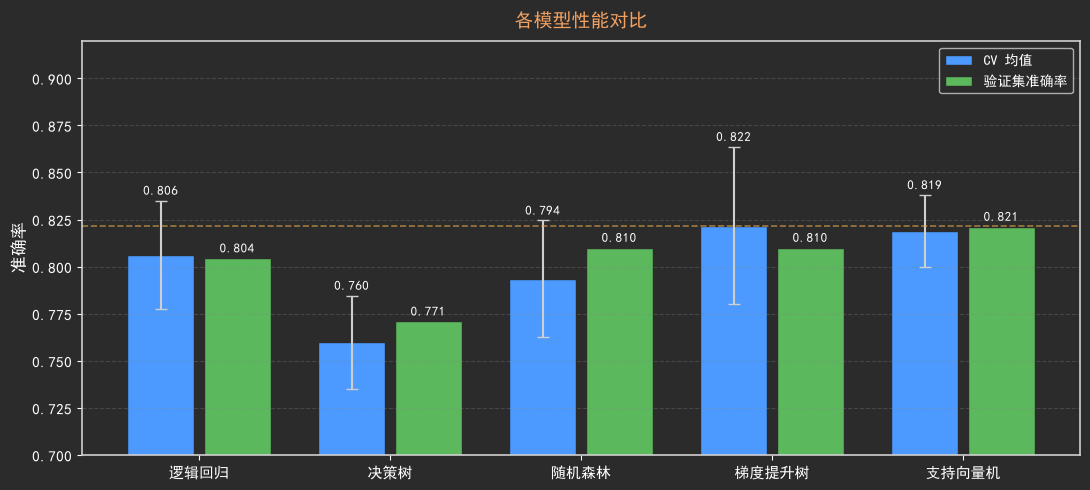

In [13]:
# 图 7：各模型性能对比
names    = list(results.keys())
cv_mean  = [results[m]['CV均值'] for m in names]
cv_std   = [results[m]['CV标准差'] for m in names]
val_accs = [results[m]['验证'] for m in names]

x   = np.arange(len(names))
fig, ax = plt.subplots(figsize=(11, 5), facecolor=BG)
ax.bar(x - 0.2, cv_mean, 0.35, label='CV 均值',
       color='#4C9AFF', yerr=cv_std, capsize=4, edgecolor=BG,
       error_kw={'ecolor': SPINE})
ax.bar(x + 0.2, val_accs, 0.35, label='验证集准确率',
       color='#5cb85c', edgecolor=BG)
ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylim(0.70, 0.92)
ax.axhline(max(cv_mean), color='#f0ad4e', linestyle='--', alpha=0.6, linewidth=1.2)
ax.legend(facecolor=BG, edgecolor=SPINE, labelcolor=FG)
dark_ax(ax, title='各模型性能对比', ylabel='准确率', grid_axis='y')
for xi, (cv, std, val) in enumerate(zip(cv_mean, cv_std, val_accs)):
    ax.text(xi - 0.2, cv + std + 0.003, f'{cv:.3f}',
            ha='center', fontsize=9, color=FG)
    ax.text(xi + 0.2, val + 0.003, f'{val:.3f}',
            ha='center', fontsize=9, color=FG)
plt.tight_layout()
save_fig(fig, 'plot_07_model_comparison.png')
plt.show()


## 第五步：选择最优模型并调优

只根据训练部分的 CV 均值选择模型，再在同一训练部分进行网格搜索。留出验证集不参与自动选择。

In [14]:
# 根据 CV 均值自动选最优模型名称
best_name = max(results, key=lambda m: results[m]['CV均值'])
print(f'CV 均值最高的模型：{best_name}  ({results[best_name]["CV均值"]:.4f})')
print()
print('所有模型 CV 均值排序：')
for n, r in sorted(results.items(), key=lambda x: x[1]['CV均值'], reverse=True):
    print(f'  {n:8s}  CV={r["CV均值"]:.4f}(+-{r["CV标准差"]:.4f})  验证={r["验证"]:.4f}')


CV 均值最高的模型：梯度提升树  (0.8218)

所有模型 CV 均值排序：
  梯度提升树     CV=0.8218(+-0.0419)  验证=0.8101
  支持向量机     CV=0.8189(+-0.0192)  验证=0.8212
  逻辑回归      CV=0.8062(+-0.0288)  验证=0.8045
  随机森林      CV=0.7936(+-0.0309)  验证=0.8101
  决策树       CV=0.7599(+-0.0247)  验证=0.7709


In [15]:
# 对 CV 最优的模型做网格搜索调优
# 这里针对梯度提升树和随机森林两种情况都预设了参数网格，
# 运行时自动匹配实际最优模型
param_grids = {
    '梯度提升树': {
        'clf__n_estimators':      [100, 200],
        'clf__max_depth':         [3, 4, 5],
        'clf__learning_rate':     [0.05, 0.1, 0.15],
        'clf__subsample':         [0.8, 1.0],
        'clf__min_samples_split': [2, 5],
    },
    '随机森林': {
        'clf__n_estimators': [100, 200],
        'clf__max_depth':    [None, 6, 10],
        'clf__min_samples_split': [2, 5],
        'clf__max_features': ['sqrt', 0.5],
    },
    '支持向量机': {
        'clf__C':     [0.1, 1, 10],
        'clf__gamma': ['scale', 'auto'],
    },
    '逻辑回归': {
        'clf__C':       [0.01, 0.1, 1, 10],
        'clf__penalty': ['l1', 'l2'],
        'clf__solver':  ['saga'],
    },
    '决策树': {
        'clf__max_depth':        [3, 5, 7, None],
        'clf__min_samples_split': [2, 5, 10],
    },
}

tune_name = best_name
param_grid = param_grids.get(tune_name, {})

if param_grid:
    base_pipe = models[tune_name]
    # 小数据集使用串行搜索，避免 Windows 多进程退出时的资源清理错误
    grid_search = GridSearchCV(
        base_pipe, param_grid, cv=5,
        scoring='accuracy', n_jobs=1, verbose=0
    )
    grid_search.fit(X_train, y_train)
    print(f'调优模型：{tune_name}')
    print('最优参数：')
    print(grid_search.best_params_)
    print(f'最优 CV 得分：{grid_search.best_score_:.4f}')
    best_pipe = grid_search.best_estimator_
else:
    best_pipe = models[tune_name]
    print(f'使用默认参数：{tune_name}')


调优模型：梯度提升树
最优参数：
{'clf__learning_rate': 0.05, 'clf__max_depth': 4, 'clf__min_samples_split': 5, 'clf__n_estimators': 100, 'clf__subsample': 0.8}
最优 CV 得分：0.8273


In [16]:
# 验证集详细评估
y_pred_val = best_pipe.predict(X_val)

print('=== 验证集评估报告 ===')
print(classification_report(y_val, y_pred_val, target_names=['遇难', '生还']))
val_acc_tuned = accuracy_score(y_val, y_pred_val)
print(f'验证集准确率：{val_acc_tuned:.4f}')


=== 验证集评估报告 ===
              precision    recall  f1-score   support

          遇难       0.82      0.87      0.85       110
          生还       0.77      0.70      0.73        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179

验证集准确率：0.8045


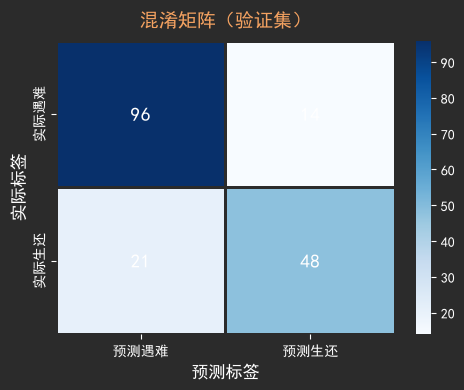

In [17]:
# 图 8：混淆矩阵
cm = confusion_matrix(y_val, y_pred_val)

fig, ax = plt.subplots(figsize=(5, 4), facecolor=BG)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=['预测遇难', '预测生还'],
            yticklabels=['实际遇难', '实际生还'],
            linewidths=1, linecolor=BG,
            annot_kws={'color': 'white', 'fontsize': 14})
ax.set_title('混淆矩阵（验证集）', fontsize=14, color=TITLE, pad=10)
ax.set_xlabel('预测标签', color=FG, fontsize=12)
ax.set_ylabel('实际标签', color=FG, fontsize=12)
ax.tick_params(colors=FG)
ax.set_facecolor(BG)
ax.figure.set_facecolor(BG)
cbar = ax.collections[0].colorbar
cbar.ax.yaxis.set_tick_params(color=FG)
plt.setp(cbar.ax.yaxis.get_ticklabels(), color=FG)
plt.tight_layout()
save_fig(fig, 'plot_08_confusion_matrix.png')
plt.show()


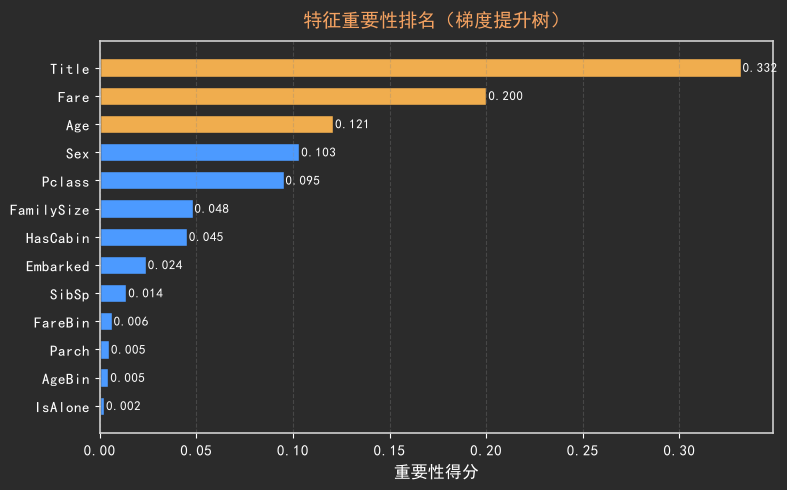

Top 5 最重要特征：
       特征       重要性
7   Title  0.331692
5    Fare  0.200140
2     Age  0.120845
1     Sex  0.103328
0  Pclass  0.095130


In [18]:
# 图 9：特征重要性（仅树模型支持）
clf_step = best_pipe.named_steps['clf']
features = best_pipe.named_steps['features'].get_feature_names_out().tolist()

if hasattr(clf_step, 'feature_importances_'):
    imp_df = pd.DataFrame({
        '特征':   features,
        '重要性': clf_step.feature_importances_
    }).sort_values('重要性', ascending=True)

    fig, ax = plt.subplots(figsize=(8, 5), facecolor=BG)
    colors = ['#f0ad4e' if i >= len(imp_df) - 3 else '#4C9AFF'
              for i in range(len(imp_df))]
    ax.barh(imp_df['特征'], imp_df['重要性'],
            color=colors, edgecolor=BG, height=0.65)
    for i, (feat, val) in enumerate(zip(imp_df['特征'], imp_df['重要性'])):
        ax.text(val + 0.001, i, f'{val:.3f}', va='center', fontsize=9, color=FG)
    dark_ax(ax, title=f'特征重要性排名（{tune_name}）',
            xlabel='重要性得分', grid_axis='x')
    plt.tight_layout()
    save_fig(fig, 'plot_09_feature_importance.png')
    plt.show()

    print('Top 5 最重要特征：')
    print(imp_df.sort_values('重要性', ascending=False).head())
else:
    print(f'{tune_name} 不支持 feature_importances_，跳过此图')


## 第六步：生成预测结果

用完整训练集（891 人）重新 fit 整个 Pipeline，再对原始测试数据的 418 名乘客预测。

全量 CV 每折仍独立拟合全部预处理；但模型和参数已通过同一数据集选出，所以分数只供参考，不是独立的泛化评估。留出集也已在项目迭代中多次查看，不应称为从未使用的最终测试集。

In [19]:
# 用全量训练集重新 fit
best_pipe.fit(X, y)

cv_final = cross_val_score(best_pipe, X, y, cv=5, scoring='accuracy')
print(f'全量 5 折 CV（供参考）：{cv_final.mean():.4f} (+-{cv_final.std():.4f})')
print('注：该分数在调参后评估，存在乐观偏差')


全量 5 折 CV（供参考）：0.8260 (+-0.0228)
注：该分数在调参后评估，存在乐观偏差


In [20]:
predictions = best_pipe.predict(X_pred)

submission = pd.DataFrame({
    'PassengerId': test['PassengerId'],
    'Survived':    predictions.astype(int)
})
submission.to_csv('submission.csv', index=False)

print('结果已保存到 submission.csv')
print(f'预测生还：{predictions.sum()} / {len(predictions)} ({predictions.mean():.1%})')
print()
print(submission.head(10))


结果已保存到 submission.csv
预测生还：149 / 418 (35.6%)

   PassengerId  Survived
0          892         0
1          893         0
2          894         0
3          895         0
4          896         0
5          897         0
6          898         0
7          899         0
8          900         1
9          901         0


In [21]:
# 打印汇总，供最终总结引用
print('=== 各模型 CV 均值排序 ===')
for n, r in sorted(results.items(), key=lambda x: x[1]['CV均值'], reverse=True):
    print(f'  {n:8s}  CV={r["CV均值"]:.4f}  验证={r["验证"]:.4f}')
print()
print(f'最终选用：{tune_name}')
print(f'调优后 CV：{grid_search.best_score_:.4f}')
print(f'留出验证：{val_acc_tuned:.4f}')
print(f'全量 CV（参考）：{cv_final.mean():.4f}')

if hasattr(clf_step, 'feature_importances_'):
    top_feats = (pd.Series(clf_step.feature_importances_, index=features)
                 .sort_values(ascending=False)
                 .head(4).index.tolist())
    print(f'Top 4 特征：{top_feats}')


=== 各模型 CV 均值排序 ===
  梯度提升树     CV=0.8218  验证=0.8101
  支持向量机     CV=0.8189  验证=0.8212
  逻辑回归      CV=0.8062  验证=0.8045
  随机森林      CV=0.7936  验证=0.8101
  决策树       CV=0.7599  验证=0.7709

最终选用：梯度提升树
调优后 CV：0.8273
留出验证：0.8045
全量 CV（参考）：0.8260
Top 4 特征：['Title', 'Fare', 'Age', 'Sex']


## 总结

### 主要发现

| 特征 | 规律 |
|------|------|
| 性别 | 女性生存率约 74%，男性约 19% |
| 船舱等级 | 一等舱约 63% > 二等舱约 47% > 三等舱约 24% |
| 年龄 | 儿童（Master）生存率偏高，老年男性最低 |
| 家庭规模 | 2~4 人家庭生存率最高，独行和超大家庭最低 |

### 评估指标

具体数字见上面 Cell 的输出（各折 CV + 留出验证集 + 全量 CV 三组对比）。
留出集不参与代码中的自动选择，但已在项目迭代中多次查看；全量 CV 的模型和参数来自同一数据集，可能存在选择偏差。两者都不等于独立测试成绩。

### 数据泄露预防措施

- 特征工程、标准化、模型都在 `Pipeline` 内，交叉验证每折独立 fit
- 预测使用训练时保存的固定统计量和分箱边界，与预测批次大小无关

### 可改进方向
- 提取 Cabin 列甲板字母（A/B/C…）
- 尝试 XGBoost / LightGBM
- 年龄段 × 性别交叉特征
- Voting / Stacking 集成